# Trabalho Prático - Exemplo resolvido: o chatbot da Biblioteca

**Inteligência Artificial - Graduação**
Prof. Bruno Nogueira - FACOM/UFMS - 2026/2

---

Este notebook percorre, de ponta a ponta, **tudo o que o seu grupo vai fazer no
trabalho**, usando um tema de exemplo: o atendimento automático de uma biblioteca
universitária (fictícia). Rode célula por célula, leia os comentários e responda
mentalmente aos `🔎 PARE E PENSE`.

> ⚠️ O tema *Biblioteca* é só ilustrativo e **não pode ser escolhido** pelos grupos.
> Os dados daqui são pequenos de propósito (cerca de 30 frases por intenção) e foram
> todos escritos com ajuda de um LLM - por isso **não** cumprem as regras do
> trabalho (o teste de vocês precisa ser escrito por pessoas). Veja a seção 13.

### O que é um chatbot de intenções

Quando alguém escreve *"dá pra renovar meu livro pelo celular?"*, o bot não precisa
"entender" a frase como uma pessoa: basta descobrir **qual é a intenção** do
usuário (aqui, `renovacao`) e entregar a resposta preparada para ela. Descobrir a
intenção é um problema de **classificação de textos** - e classificação é
exatamente o que estudamos nas últimas aulas.

Mas há um detalhe que separa um bot útil de um bot irritante: nem toda mensagem
tem resposta. *"oi"* pede uma saudação; *"vai chover amanhã?"* pede uma recusa
educada. Um classificador treinado só com as intenções do domínio vai, mesmo assim,
escolher **alguma** intenção para a previsão do tempo - e responder bobagem com
toda a confiança. Por isso o nosso bot usa **dois classificadores em cascata**:

```
                   ┌────────────────────┐
  mensagem ──────▶ │ 1. ESCOPO          │──── chitchat ─────▶ resposta social
                   │ (3 classes)        │──── fora_dominio ─▶ recusa educada
                   └─────────┬──────────┘
                             │ dominio
                   ┌─────────▼──────────┐
                   │ 2. TEMA            │──── confiança baixa ─▶ "você quis dizer...?"
                   │ (N intenções)      │──── emprestimo ──────▶ resposta de empréstimo
                   └────────────────────┘──── renovacao ───────▶ resposta de renovação
                                         └─── ...
```

Quem decide para onde cada mensagem vai é um **grafo de estados**, montado com a
biblioteca [LangGraph](https://langchain-ai.github.io/langgraph/). O grafo já vem
pronto no código base; o trabalho de vocês é construir os **dados** e os
**classificadores** que o alimentam - e analisar, com o método da aula 05, o que
funciona e por quê.

### Roteiro

| # | Seção | O que se aprende |
|---|-------|------------------|
| 0 | Ambiente | rodar no computador ou no Colab |
| 1 | Configuração | o arquivo `grupo.yaml` |
| 2 | Os dados | formato, rótulos, negativos difíceis |
| 3 | Texto → números | saco de palavras, TF-IDF, n-gramas de caracteres |
| 4 | Classificador de escopo | comparar algoritmos com validação cruzada |
| 5 | Classificador de tema | o mesmo, só com as mensagens do domínio |
| 6 | Abrindo a caixa | que palavras o modelo aprendeu |
| 7 | Salvar os modelos | o "contrato" com a avaliação |
| 8 | LangGraph | nós, estado e arestas condicionais |
| 9 | Limiar de confiança | quando o bot deve perguntar em vez de responder |
| 10 | Conversa com memória | o histórico no estado do grafo |
| 11 | O LLM entra em cena (RAG) | documentos, índice vetorial, busca e OpenRouter |
| 12 | Avaliação final | o script padronizado de correção |
| 13 | E agora? | o que muda no trabalho do seu grupo |

---
## 0. Preparando o ambiente

A célula abaixo funciona em três situações: no seu computador (com o repositório
clonado), no Docker da disciplina e no Google Colab. No Colab, ela clona o
repositório e instala as dependências - **troque `REPO_URL` pelo endereço do
repositório do seu grupo**.

In [ ]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/bmnogueira-ufms/IA-2026-02-TP-Chatbot.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Sobe de diretório até achar a raiz do repositório (a pasta que contém chatbot/)
raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))
print("Raiz do repositório:", raiz)

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Código base do trabalho (pasta chatbot/ do repositório)
from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO
from chatbot.texto import normalizar

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.figsize": (7, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]

---
## 1. A configuração do grupo: `grupo.yaml`

Tudo o que é específico de um tema fica num único arquivo YAML: nome do grupo, as
intenções (com uma descrição curta e a resposta do bot), onde estão os dados e os
modelos, e o limiar de confiança. O código base, os notebooks e o script de
avaliação leem **o mesmo arquivo** - é isso que permite ao professor corrigir
trabalhos de temas diferentes com um único script.

O exemplo fica em `exemplos/biblioteca/grupo.yaml`; o do seu grupo, em
`grupo.yaml`, na raiz do repositório.

In [3]:
config = carregar_config("exemplos/biblioteca/grupo.yaml")

print("Tema:", config.tema)
print("Limiar de confiança do tema:", config.limiar_tema)
pd.DataFrame(
    [(i.nome, i.descricao, i.resposta[:70] + "...") for i in config.intencoes.values()],
    columns=["intenção", "descrição", "resposta (início)"],
)

Tema: Biblioteca universitária
Limiar de confiança do tema: 0.35


,intenção,descrição,resposta (início)
0,emprestimo,empréstimo de livros,Alunos de graduação podem levar até 5 livros por 14 dias; alunos de pó...
1,renovacao,renovação de empréstimos,"A renovação é feita pelo site ou pelo aplicativo, em ""Meus empréstimos..."
2,multa,"multas, atrasos e pendências",Cada dia de atraso gera 1 dia de suspensão por livro. Livros perdidos ...
3,horario,horários de funcionamento,"A biblioteca central funciona de segunda a sexta, das 7h às 22h, e aos..."
4,reserva_sala,reserva de salas e cabines de estudo,Salas de grupo (até 6 pessoas) e cabines individuais são reservadas pe...
5,acesso_bases,"acesso a periódicos, e-books e bases digitais","Fora do campus, acesse o Portal de Periódicos CAPES pelo ""Acesso CAFe""..."


---
## 2. Os dados

Cada linha dos arquivos `treino.csv` e `teste.csv` é uma mensagem com **um** rótulo,
a coluna `intencao`, que pode ser:

* uma das intenções do domínio (`emprestimo`, `renovacao`, ...);
* `chitchat` - conversa social (saudação, agradecimento, "você é um robô?");
* `fora_dominio` - pedidos legítimos que o bot não sabe atender.

A coluna `origem` registra de onde veio a frase (`humano`, `coletado`, `llm`,
`aumentado`, `massive`). Ela não é usada pelos classificadores, mas é essencial para
**discutir** os resultados: um modelo treinado só com frases de LLM vai bem em
frases de LLM e... em frases de pessoas?

In [4]:
treino = carregar_dados(config.treino)
teste = carregar_dados(config.teste)

print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Frases do teste repetidas no treino:", vazamento(treino, teste) or "nenhuma")
treino.sample(8, random_state=RANDOM_STATE)

Problemas no treino: nenhum
Problemas no teste:  nenhum
Frases do teste repetidas no treino: nenhuma


,texto,intencao,origem
231,você não entendeu nada,chitchat,llm
110,horário de funcionamento durante a greve,horario,llm
250,qual o cardápio do RU hoje?,fora_dominio,llm
9,dá pra emprestar livro sem estar matriculado?,emprestimo,llm
93,posso pagar a multa com pix?,multa,llm
220,tudo bom?,chitchat,llm
309,como chego no shopping de ônibus?,fora_dominio,llm
199,valeu,chitchat,llm


In [5]:
resumo(treino)

origem,llm,total
intencao,,
acesso_bases,31,31
chitchat,60,60
emprestimo,35,35
fora_dominio,79,79
horario,31,31
multa,30,30
renovacao,30,30
reserva_sala,32,32
total,328,328


O rótulo do **1º classificador** (escopo) não precisa ser anotado: ele é derivado da
intenção. Toda intenção do domínio vira `dominio`.

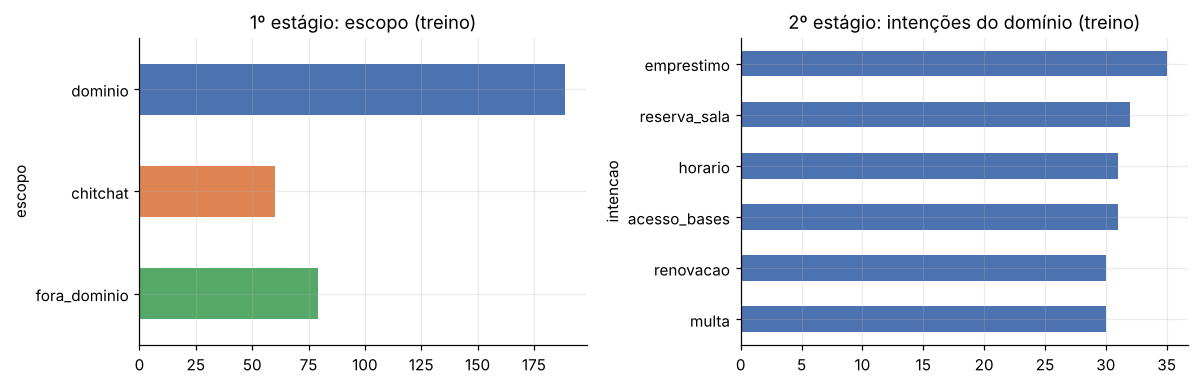

In [6]:
treino = adicionar_escopo(treino, config)
teste = adicionar_escopo(teste, config)

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
treino["escopo"].value_counts().reindex(CLASSES_ESCOPO).plot.barh(ax=eixos[0], color=CORES[:3])
eixos[0].set_title("1º estágio: escopo (treino)")
eixos[0].invert_yaxis()
treino.loc[treino["escopo"] == "dominio", "intencao"].value_counts().plot.barh(ax=eixos[1], color=CORES[0])
eixos[1].set_title("2º estágio: intenções do domínio (treino)")
eixos[1].invert_yaxis()
plt.tight_layout()
plt.show()

### Negativos fáceis e negativos difíceis

Olhe com atenção as frases `fora_dominio` do treino. Algumas são **fáceis**: nada
têm a ver com bibliotecas (*"toca uma música"*, *"vai chover amanhã?"*). Outras
foram escritas para **enganar** o classificador:

In [7]:
dificeis = ["como renovo meu passaporte?", "quanto é a multa de trânsito por excesso de velocidade?",
            "que horas o RU abre?", "como reservo uma quadra no ginásio?",
            "onde compro o livro do Stewart mais barato?"]
treino[treino["texto"].isin(dificeis)][["texto", "intencao"]]

,texto,intencao
277,que horas o RU abre?,fora_dominio
281,onde compro o livro do Stewart mais barato?,fora_dominio
287,como renovo meu passaporte?,fora_dominio
290,quanto é a multa de trânsito por excesso de velocidade?,fora_dominio
291,como reservo uma quadra no ginásio?,fora_dominio


> 🔎 **PARE E PENSE.** *"como renovo meu passaporte?"* tem a palavra **renovo**;
> *"que horas o RU abre?"* tem **que horas** e **abre** - as mesmas pistas de
> `renovacao` e `horario`. O que um classificador aprenderia se o `fora_dominio`
> tivesse **só** negativos fáceis? Qual palavra ele usaria para decidir que uma
> mensagem é da biblioteca?

Esses **negativos difíceis** (assuntos *vizinhos* ao seu tema) são a parte mais
importante - e mais trabalhosa - dos dados do seu grupo.

---
## 3. De texto para números

Regressão logística, redes neurais e árvores recebem **vetores**, não frases.
Precisamos de uma função texto → vetor.

### 3.1 Saco de palavras (*bag of words*)

A ideia mais simples: montar um vocabulário com todas as palavras do treino e
representar cada frase pela **contagem** de cada palavra. A ordem das palavras se
perde (daí o "saco").

In [8]:
frases = ["quero renovar meu livro",
          "quero pegar um livro emprestado",
          "a biblioteca abre no sábado?"]
contador = CountVectorizer(preprocessor=normalizar)
X_contagem = contador.fit_transform(frases)
pd.DataFrame(X_contagem.toarray(), columns=contador.get_feature_names_out(), index=frases)

,abre,biblioteca,emprestado,livro,meu,no,pegar,quero,renovar,sabado,um
quero renovar meu livro,0,0,0,1,1,0,0,1,1,0,0
quero pegar um livro emprestado,0,0,1,1,0,0,1,1,0,0,1
a biblioteca abre no sábado?,1,1,0,0,0,1,0,0,0,1,0


### 3.2 TF-IDF

Contagem bruta dá o mesmo peso a "quero" (aparece em muitas frases, não diz nada)
e a "renovar" (rara e decisiva). O **TF-IDF** corrige isso multiplicando a
frequência do termo na frase (TF) pelo inverso da frequência entre as frases (IDF):

$$\text{tfidf}(t, d) = \text{tf}(t, d)\cdot\left(\ln\frac{1 + n}{1 + \text{df}(t)} + 1\right)$$

onde $n$ é o número de frases e $\text{df}(t)$ é em quantas delas o termo $t$
aparece. Depois, cada vetor é normalizado para ter comprimento 1.

In [9]:
tfidf = TfidfVectorizer(preprocessor=normalizar)
X_tfidf = tfidf.fit_transform(frases)
pd.DataFrame(X_tfidf.toarray(), columns=tfidf.get_feature_names_out(), index=frases).round(2)

,abre,biblioteca,emprestado,livro,meu,no,pegar,quero,renovar,sabado,um
quero renovar meu livro,0.0,0.0,0.00,0.43,0.56,0.0,0.00,0.43,0.56,0.0,0.00
quero pegar um livro emprestado,0.0,0.0,0.49,0.37,0.00,0.0,0.49,0.37,0.00,0.0,0.49
a biblioteca abre no sábado?,0.5,0.5,0.00,0.00,0.00,0.5,0.00,0.00,0.00,0.5,0.00


Repare: na primeira frase, "renovar" pesa mais que "quero" e "livro", que se
repetem em outras frases.

### 3.3 N-gramas de caracteres: robustez a erros de digitação

Em chat, ninguém revisa o que escreve: *"renovaçao"*, *"renvar"*, *"q horas abre a
bibli"*. Para o TF-IDF de palavras, "renvar" é uma palavra **nova**, que não existe
no vocabulário - o vetor fica zerado nessa posição. Uma alternativa é quebrar o
texto em pedaços de 2 a 5 caracteres (n-gramas de caracteres): "renvar" ainda
compartilha "re", "ren", "var", "ar"... com "renovar".

In [10]:
def similaridade(vetorizador, a, b, corpus):
    """Cosseno entre os vetores TF-IDF de duas frases (vetores já normalizados)."""
    vetorizador.fit(corpus)
    va, vb = vetorizador.transform([a, b]).toarray()
    return float(va @ vb)


corpus = treino["texto"].tolist()
pares = [("quero renovar meu livro", "qro renvar meu livro"),
         ("quero renovar meu livro", "renovaçao do emprestimo"),
         ("quero renovar meu livro", "a biblioteca abre no sábado?")]
pd.DataFrame(
    [(a, b, similaridade(tfidf_palavras(), a, b, corpus), similaridade(tfidf_caracteres(), a, b, corpus))
     for a, b in pares],
    columns=["frase A", "frase B", "cosseno (palavras)", "cosseno (caracteres)"],
).round(2)

,frase A,frase B,cosseno (palavras),cosseno (caracteres)
0,quero renovar meu livro,qro renvar meu livro,0.56,0.58
1,quero renovar meu livro,renovaçao do emprestimo,0.00,0.23
2,quero renovar meu livro,a biblioteca abre no sábado?,0.00,0.02


Os vetorizadores `tfidf_palavras()` e `tfidf_caracteres()` estão em
`chatbot/representacoes.py`, já configurados com a normalização de
`chatbot/texto.py` (minúsculas, sem acentos, sem pontuação). Quantas dimensões
cada um gera no nosso treino?

In [11]:
for nome, vet in [("palavras (1-2 gramas)", tfidf_palavras()), ("caracteres (2-5 gramas)", tfidf_caracteres())]:
    print(f"{nome:25s}: {vet.fit_transform(corpus).shape[1]:6d} dimensões para {len(corpus)} frases")

palavras (1-2 gramas)    :   1691 dimensões para 328 frases
caracteres (2-5 gramas)  :   5538 dimensões para 328 frases


> 🔎 **PARE E PENSE.** Milhares de dimensões e poucas centenas de exemplos. Pela
> aula 05, que risco isso traz? Que hiperparâmetro da regressão logística ajuda a
> controlá-lo?

---
## 4. O classificador de escopo (1º estágio)

Vamos comparar **três algoritmos** vistos na disciplina, cada um com **duas
representações**. Um `Pipeline` encadeia vetorizador e classificador: assim o
vocabulário e o IDF são aprendidos **só com os folds de treino** de cada rodada da
validação cruzada - sem vazamento (aula 02).

Métrica principal: **F1 macro** (média do F1 das classes), porque as classes são
desbalanceadas e todas importam (aula 01).

> Nesta fase **não tocamos no teste**. Toda escolha é feita com validação cruzada
> estratificada no treino (aula 05). O teste será usado uma única vez, na seção 11.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
}
CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
}


def comparar(textos, rotulos):
    """Validação cruzada de todas as combinações representação × classificador."""
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(),
                           "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.813,0.033,0.844,1.0
1,TF-IDF caracteres,Rede neural (MLP),0.782,0.042,0.823,1.0
2,TF-IDF palavras,Rede neural (MLP),0.764,0.038,0.802,1.0
3,TF-IDF palavras,Regressão logística,0.719,0.055,0.777,1.0
4,TF-IDF caracteres,Árvore de decisão,0.682,0.036,0.729,1.0
5,TF-IDF palavras,Árvore de decisão,0.636,0.062,0.686,1.0


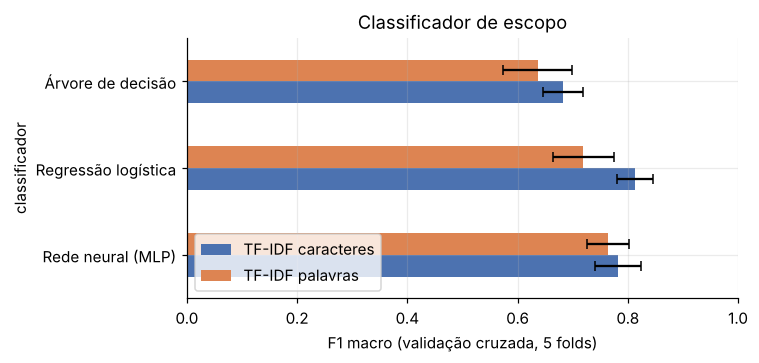

In [13]:
def grafico_comparacao(tab, titulo):
    piv = tab.pivot(index="classificador", columns="representação", values="F1 macro (CV)")
    err = tab.pivot(index="classificador", columns="representação", values="desvio")
    ax = piv.plot.barh(xerr=err, color=CORES[:2], figsize=(7, 3.4), capsize=3)
    ax.set_xlabel("F1 macro (validação cruzada, 5 folds)")
    ax.set_xlim(0, 1)
    ax.set_title(titulo)
    ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


grafico_comparacao(tab_escopo, "Classificador de escopo")

> 🔎 **PARE E PENSE.** Compare a coluna "F1 macro (treino)" com "F1 macro (CV)" da
> árvore de decisão. Que diagnóstico da aula 05 isso sugere: viés alto ou variância
> alta? E o desvio entre folds - com cerca de 300 frases, diferenças de 1 ou 2
> pontos entre modelos são confiáveis?

### 4.1 Ajustando o hiperparâmetro `C`

A combinação com melhor F1 foi regressão logística + caracteres. Lembre-se da aula
05: na regressão logística do scikit-learn, **`C = 1/λ`** - quanto menor o `C`, mais
forte a regularização. Vamos escolhê-lo com `GridSearchCV` (também só no treino).

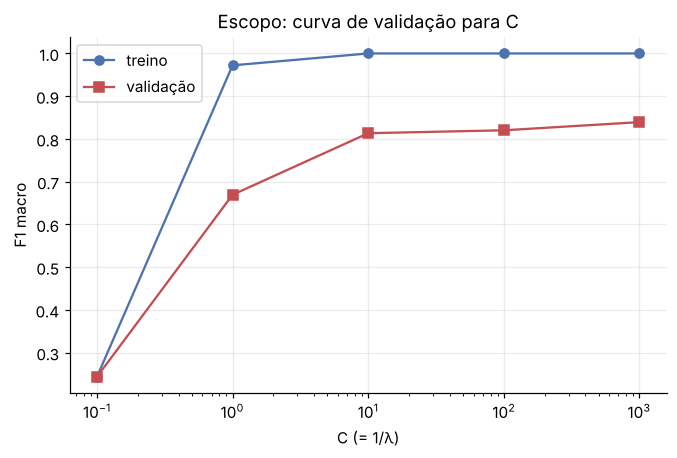

Melhor C: 1000 | F1 macro (CV) = 0.839


In [14]:
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100, 1000]},
    scoring="f1_macro", cv=cv, return_train_score=True,
)
busca_escopo.fit(treino["texto"], treino["escopo"])

res = pd.DataFrame(busca_escopo.cv_results_)
ax = plt.gca()
ax.semilogx(res["param_classificador__C"].astype(float), res["mean_train_score"], "o-", color=CORES[0], label="treino")
ax.semilogx(res["param_classificador__C"].astype(float), res["mean_test_score"], "s-", color=CORES[3], label="validação")
ax.set_xlabel("C (= 1/λ)")
ax.set_ylabel("F1 macro")
ax.set_title("Escopo: curva de validação para C")
ax.legend()
plt.show()
print("Melhor C:", busca_escopo.best_params_["classificador__C"],
      f"| F1 macro (CV) = {busca_escopo.best_score_:.3f}")

> 🔎 **PARE E PENSE.** O melhor `C` caiu na **borda** da grade (o maior valor
> testado), ou seja, quase sem regularização - e o F1 de treino é 1,0 para todos os
> valores. Pela aula 05, o que fazer quando o ótimo está na borda? E por que, com
> milhares de dimensões e poucas frases, quase qualquer modelo decora o treino? No
> trabalho, explore grades maiores e discuta o que acontece com as
> **probabilidades** quando a regularização some (voltaremos a isso na seção 9).

### 4.2 Onde o classificador de escopo erra

`cross_val_predict` devolve, para cada frase do treino, a previsão feita pelo
modelo do fold em que ela **não** foi usada no treino. É uma forma honesta de
montar uma matriz de confusão sem tocar no teste.

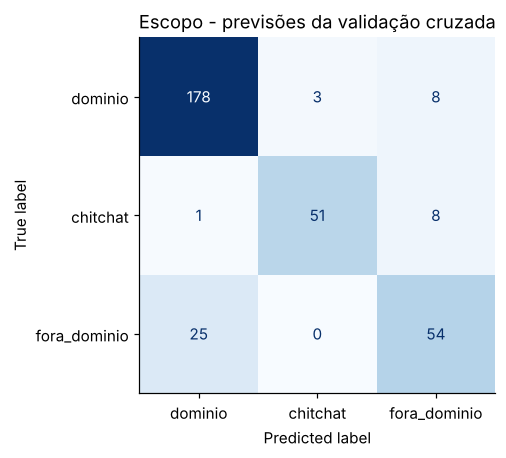

,texto,escopo,previsto
85,minha suspensão termina quando?,dominio,fora_dominio
94,a multa dobra no fim de semana?,dominio,fora_dominio
98,até que horas fica aberta hoje?,dominio,fora_dominio
100,vai abrir no feriado?,dominio,chitchat
110,horário de funcionamento durante a greve,dominio,fora_dominio
120,fecha mais cedo na sexta?,dominio,chitchat
127,como agendo uma cabine individual?,dominio,fora_dominio
129,como reservo uma sala para meu grupo de TCC?,dominio,fora_dominio
169,vocês assinam a web of science?,dominio,chitchat
180,como faço comutação bibliográfica?,dominio,fora_dominio


In [15]:
clf_escopo = busca_escopo.best_estimator_
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.title("Escopo - previsões da validação cruzada")
plt.grid(False)
plt.show()

erros = treino.assign(previsto=prev_cv).query("escopo != previsto")
erros[["texto", "escopo", "previsto"]]

> 🔎 **PARE E PENSE.** Num chatbot há dois erros bem diferentes:
> * **falso aceite** - algo `fora_dominio` previsto como `dominio`: o bot responde
>   com confiança uma coisa que não tem nada a ver;
> * **falsa recusa** - algo do `dominio` previsto como `fora_dominio`: o usuário
>   ouve "não sei" sobre um assunto que o bot sabia.
>
> Qual dos dois é pior para a biblioteca? E para um bot de matrícula na véspera do
> prazo? A resposta muda qual métrica (precisão ou revocação de qual classe) o grupo
> deveria priorizar - discuta isso no relatório.

---
## 5. O classificador de tema (2º estágio)

O segundo classificador só vê mensagens que o primeiro já considerou do domínio.
Por isso ele é treinado **apenas** com as frases cujo escopo é `dominio` - não faz
sentido gastar capacidade do modelo separando "toca uma música" de "renovar livro":
isso já é trabalho do estágio 1.

In [16]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.866,0.070,0.868,1.0
1,TF-IDF caracteres,Rede neural (MLP),0.807,0.105,0.810,1.0
2,TF-IDF palavras,Regressão logística,0.790,0.087,0.788,1.0
3,TF-IDF palavras,Rede neural (MLP),0.726,0.088,0.724,1.0
4,TF-IDF caracteres,Árvore de decisão,0.636,0.043,0.640,1.0
5,TF-IDF palavras,Árvore de decisão,0.627,0.091,0.630,1.0


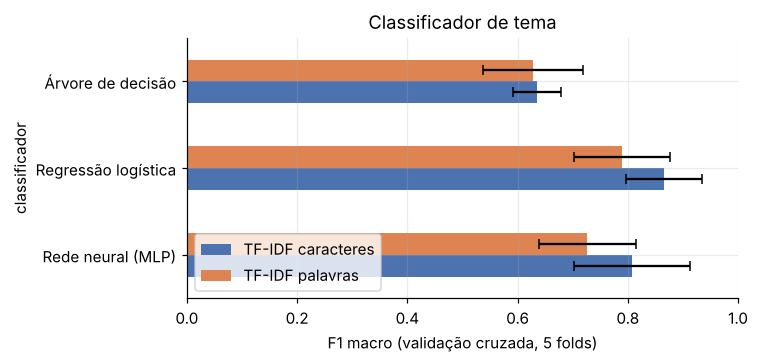

In [17]:
grafico_comparacao(tab_tema, "Classificador de tema")

Melhor C: 1000 | F1 macro (CV) = 0.876


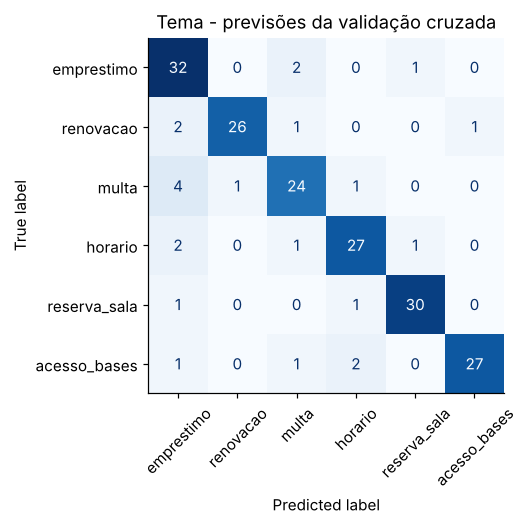

              precision    recall  f1-score   support

acesso_bases       0.96      0.87      0.92        31
  emprestimo       0.76      0.91      0.83        35
     horario       0.87      0.87      0.87        31
       multa       0.83      0.80      0.81        30
   renovacao       0.96      0.87      0.91        30
reserva_sala       0.94      0.94      0.94        32

    accuracy                           0.88       189
   macro avg       0.89      0.88      0.88       189
weighted avg       0.89      0.88      0.88       189



In [18]:
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.1, 1, 10, 100, 1000]},
    scoring="f1_macro", cv=cv,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print("Melhor C:", busca_tema.best_params_["classificador__C"],
      f"| F1 macro (CV) = {busca_tema.best_score_:.3f}")

prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Tema - previsões da validação cruzada")
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

> 🔎 **PARE E PENSE.** Que pares de intenções mais se confundem? Leia as frases
> erradas abaixo. O erro é do modelo ou a fronteira entre as intenções é ambígua
> até para uma pessoa? (Ex.: *"esqueci de renovar ontem, ainda dá?"* é `renovacao`
> ou `multa`?) Quando duas intenções se confundem demais, às vezes a solução é
> **redesenhar as intenções**, não trocar de algoritmo.

In [19]:
treino_dom.assign(previsto=prev_tema).query("intencao != previsto")[["texto", "intencao", "previsto"]]

,texto,intencao,previsto
14,o livro de referência pode sair da biblioteca?,emprestimo,multa
15,quero levar um livro pra estudar no fim de semana,emprestimo,reserva_sala
31,onde eu devolvo o livro quando a biblioteca está fechada?,emprestimo,multa
42,consigo prorrogar a data de devolução?,renovacao,acesso_bases
51,quero mais uma semana com o livro de física,renovacao,emprestimo
58,quero adiar a devolução do livro,renovacao,emprestimo
59,como faço pra não ter que devolver o livro agora,renovacao,multa
74,perdi o livro da biblioteca e agora?,multa,horario
75,danifiquei um livro emprestado o que faço,multa,emprestimo
81,derrubei café no livro vou ter que pagar?,multa,emprestimo


---
## 6. Abrindo a caixa: o que a regressão logística aprendeu

Uma vantagem da regressão logística é ser **interpretável**: na versão multiclasse
ela tem um vetor de pesos $\theta$ por classe, e cada dimensão corresponde a um termo
do vocabulário. Os termos com maior peso são as "pistas" que o modelo usa. Para
ficar legível, treinamos aqui uma versão com TF-IDF de **palavras**.

In [20]:
interpretavel = Pipeline([("vetorizador", tfidf_palavras()),
                          ("classificador", LogisticRegression(C=10, max_iter=2000))])
interpretavel.fit(treino_dom["texto"], treino_dom["intencao"])
termos = interpretavel["vetorizador"].get_feature_names_out()
pesos = interpretavel["classificador"].coef_

pd.DataFrame({
    classe: [termos[j] for j in np.argsort(pesos[i])[::-1][:8]]
    for i, classe in enumerate(interpretavel["classificador"].classes_)
})

,acesso_bases,emprestimo,horario,multa,renovacao,reserva_sala
0,acesso,livro,biblioteca,multa,renovar,sala
1,artigo,pegar,horario,atraso,renovacao,cabine
2,periodicos,um livro,abre,pendencia,renovo,salas
3,capes,emprestimo,horas,suspensao,nao,de estudo
4,da,um,que horas,bloqueado,posso renovar,estudo
5,tem,livros,qual horario,na biblioteca,data,reservar
6,book,ou,biblioteca abre,por atraso,de renovar,reservar sala
7,como,pode,fecha,se,renovacoes,sala de


> 🔎 **PARE E PENSE.** As pistas fazem sentido? Alguma delas é um "atalho" que só
> funciona por acaso nestes dados (uma palavra que aparece numa classe só porque
> quem escreveu as frases tinha esse vício)? É assim que dados gerados por um único
> LLM com um único *prompt* enganam: o modelo aprende o estilo do gerador, não a
> intenção.

---
## 7. Salvando os modelos: o "contrato" com a avaliação

O script de correção não roda o seu notebook: ele **carrega os modelos salvos** e
chama `predict`/`predict_proba`. Por isso existe um contrato (detalhado em
`chatbot/modelos.py`):

* classificador de escopo com as classes **exatamente** `dominio`, `chitchat` e `fora_dominio`;
* classificador de tema com **exatamente** as intenções do `grupo.yaml`;
* os dois aceitando **uma lista de textos crus** - por isso o vetorizador vai
  *dentro* do `Pipeline`.

`salvar_classificadores` confere o contrato antes de salvar e grava as versões das
bibliotecas em `modelos/versoes.json`.

> Antes de salvar, re-treinamos com **todo** o treino - o `GridSearchCV` já faz
> isso automaticamente com a melhor configuração (`refit=True`).

In [21]:
salvar_classificadores(clf_escopo, clf_tema, config)
print("Salvos em:", config.modelo_escopo.parent)
print(open(config.modelo_escopo.parent / "versoes.json").read())

Salvos em: /home/claude/tp/exemplos/biblioteca/modelos
{
  "python": "3.13.16",
  "scikit-learn": "1.9.1",
  "salvo_em": "2026-10-09T09:43:43"
}


---
## 8. O chatbot como um grafo de estados (LangGraph)

### 8.1 Um grafo de brinquedo

Antes do grafo de verdade, um minúsculo, para ver as três peças do LangGraph:

1. o **estado** - um dicionário tipado que viaja pelo grafo;
2. os **nós** - funções que recebem o estado e devolvem **só o que mudou**;
3. as **arestas** - fixas (`add_edge`) ou **condicionais** (`add_conditional_edges`),
   em que uma função lê o estado e escolhe o próximo nó.

In [22]:
from typing import TypedDict

from langgraph.graph import END, START, StateGraph


class EstadoBrinquedo(TypedDict, total=False):
    mensagem: str
    pergunta: bool
    resposta: str


def analisar(estado: EstadoBrinquedo) -> dict:
    return {"pergunta": estado["mensagem"].strip().endswith("?")}


def responder_pergunta(estado: EstadoBrinquedo) -> dict:
    return {"resposta": "Boa pergunta! Vou pensar..."}


def responder_afirmacao(estado: EstadoBrinquedo) -> dict:
    return {"resposta": "Entendi."}


def rotear(estado: EstadoBrinquedo) -> str:          # a função da aresta condicional
    return "sim" if estado["pergunta"] else "nao"


g = StateGraph(EstadoBrinquedo)
g.add_node("analisar", analisar)
g.add_node("responder_pergunta", responder_pergunta)
g.add_node("responder_afirmacao", responder_afirmacao)
g.add_edge(START, "analisar")
g.add_conditional_edges("analisar", rotear, {"sim": "responder_pergunta", "nao": "responder_afirmacao"})
g.add_edge("responder_pergunta", END)
g.add_edge("responder_afirmacao", END)
brinquedo = g.compile()

print(brinquedo.invoke({"mensagem": "a biblioteca abre hoje?"}))
print(brinquedo.invoke({"mensagem": "gostei da biblioteca"}))

{'mensagem': 'a biblioteca abre hoje?', 'pergunta': True, 'resposta': 'Boa pergunta! Vou pensar...'}
{'mensagem': 'gostei da biblioteca', 'pergunta': False, 'resposta': 'Entendi.'}


Troque a regra de `analisar` (terminar com "?") por um **classificador treinado** e
você tem exatamente a ideia do trabalho.

### 8.2 O grafo do chatbot

`chatbot/grafo.py` monta o grafo completo a partir do `grupo.yaml` e dos dois
classificadores. Os nós das intenções (`intencao_emprestimo`, ...) são criados
automaticamente, um por intenção. O LangGraph descreve o grafo na linguagem
**Mermaid** - cole o texto abaixo em <https://mermaid.live> para vê-lo desenhado
(ótimo para o relatório).

In [23]:
grafo = construir_grafo(config, clf_escopo, clf_tema)
print(grafo.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classificar_escopo(classificar_escopo)
	classificar_tema(classificar_tema)
	responder_chitchat(responder_chitchat)
	recusar(recusar)
	esclarecer(esclarecer)
	intencao_emprestimo(intencao_emprestimo)
	intencao_renovacao(intencao_renovacao)
	intencao_multa(intencao_multa)
	intencao_horario(intencao_horario)
	intencao_reserva_sala(intencao_reserva_sala)
	intencao_acesso_bases(intencao_acesso_bases)
	__end__([<p>__end__</p>]):::last
	__start__ --> classificar_escopo;
	classificar_escopo -. &nbsp;dominio&nbsp; .-> classificar_tema;
	classificar_escopo -. &nbsp;fora_dominio&nbsp; .-> recusar;
	classificar_escopo -. &nbsp;chitchat&nbsp; .-> responder_chitchat;
	classificar_tema -.-> esclarecer;
	classificar_tema -. &nbsp;acesso_bases&nbsp; .-> intencao_acesso_bases;
	classificar_tema -. &nbsp;emprestimo&nbsp; .-> intencao_emprestimo;
	classificar_tema -. &nbsp;horario&nbsp; .-> intencao_horario;
	

Cada `invoke` devolve o **estado final**: além da `resposta`, ficam registrados a
saída de cada classificador, a confiança e a `rota` (o nó por onde a mensagem
saiu). É a `rota` que o script de avaliação compara com o rótulo verdadeiro.

In [24]:
mensagens = ["oi, bom dia!", "consigo renovar pelo app?", "qual o cardápio do RU?",
             "abre sábado?", "perdi o livro, e agora?", "livro", "obrigado, até mais"]
linhas = []
for m in mensagens:
    e = grafo.invoke({"mensagem": m})
    linhas.append({"mensagem": m, "escopo": e["escopo"], "conf. escopo": e["confianca_escopo"],
                   "intenção": e.get("intencao"), "conf. intenção": e.get("confianca_intencao"),
                   "rota": e["rota"], "resposta": e["resposta"][:55] + "..."})
pd.DataFrame(linhas).round(2)

,mensagem,escopo,conf. escopo,intenção,conf. intenção,rota,resposta
0,"oi, bom dia!",chitchat,1.00,NaN,0.00,chitchat,Olá! Sou o assistente da biblioteca. Como posso ajudar?...
1,consigo renovar pelo app?,dominio,1.00,renovacao,1.00,renovacao,"A renovação é feita pelo site ou pelo aplicativo, em ""M..."
2,qual o cardápio do RU?,fora_dominio,0.99,NaN,0.00,fora_dominio,"Desculpe, só sei responder sobre a biblioteca: emprésti..."
3,abre sábado?,dominio,0.58,horario,0.98,horario,"A biblioteca central funciona de segunda a sexta, das 7..."
4,"perdi o livro, e agora?",dominio,1.00,multa,0.97,multa,Cada dia de atraso gera 1 dia de suspensão por livro. L...
5,livro,dominio,1.00,emprestimo,1.00,emprestimo,Alunos de graduação podem levar até 5 livros por 14 dia...
6,"obrigado, até mais",chitchat,1.00,NaN,0.00,chitchat,Por nada! Bons estudos....


---
## 9. Limiar de confiança: quando é melhor perguntar

A regressão logística devolve probabilidades (aula 03). Se a maior probabilidade do
classificador de tema for baixa - digamos, 0,30 para `emprestimo` e 0,28 para
`renovacao` -, o bot está essencialmente chutando. Nesses casos o grafo pode
desviar para o nó `esclarecer`, que pergunta ao usuário entre as duas opções mais
prováveis. O limiar fica em `roteamento.limiar_tema` no `grupo.yaml`.

Como escolher o limiar sem olhar o teste? De novo, com as probabilidades da
validação cruzada: comparamos a confiança das previsões **certas** e **erradas**.

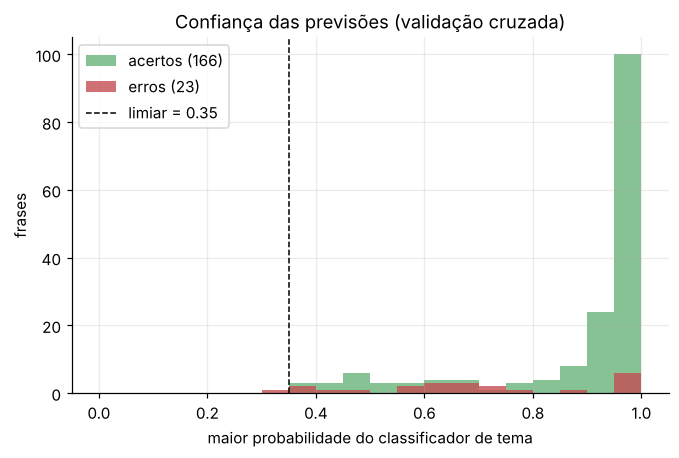

,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.878,0,0
1,0.20,1.000,0.878,0,0
2,0.30,1.000,0.878,0,0
3,0.35,0.995,0.883,1,0
4,0.40,0.968,0.891,3,3
5,0.50,0.910,0.895,5,12
6,0.60,0.868,0.902,7,18


In [25]:
proba_cv = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv,
                             method="predict_proba")
classes = np.array(sorted(treino_dom["intencao"].unique()))
confianca = proba_cv.max(axis=1)
acertou = classes[proba_cv.argmax(axis=1)] == treino_dom["intencao"].to_numpy()

bins = np.linspace(0, 1, 21)
plt.hist(confianca[acertou], bins=bins, alpha=0.7, color=CORES[2], label=f"acertos ({acertou.sum()})")
plt.hist(confianca[~acertou], bins=bins, alpha=0.8, color=CORES[3], label=f"erros ({(~acertou).sum()})")
plt.axvline(config.limiar_tema, color="k", ls="--", lw=1, label=f"limiar = {config.limiar_tema}")
plt.xlabel("maior probabilidade do classificador de tema")
plt.ylabel("frases")
plt.title("Confiança das previsões (validação cruzada)")
plt.legend()
plt.show()

linhas = []
for limiar in [0.0, 0.2, 0.3, 0.35, 0.4, 0.5, 0.6]:
    respondidas = confianca >= limiar
    linhas.append({"limiar": limiar,
                   "% respondidas direto": respondidas.mean(),
                   "acurácia nas respondidas": acertou[respondidas].mean() if respondidas.any() else np.nan,
                   "erros evitados": int((~acertou & ~respondidas).sum()),
                   "acertos que viraram pergunta": int((acertou & ~respondidas).sum())})
pd.DataFrame(linhas).round(3)

> 🔎 **PARE E PENSE.** Subir o limiar troca **erros** por **perguntas**. Toda pergunta
> a mais é um atrito com o usuário - mas toda resposta errada também. Onde você
> colocaria o limiar? Repare que a escolha depende de o modelo estar **calibrado**
> (probabilidade 0,8 significar ~80% de acerto) - e o `C` interfere nisso: com `C`
> muito grande as probabilidades ficam extremas.

In [26]:
for m in ["livro", "quero o livro de cálculo mas está atrasado"]:
    e = grafo.invoke({"mensagem": m})
    print(f"{m!r}\n   candidatas: {[(c, round(p, 2)) for c, p in e['candidatas'][:3]]}"
          f"\n   rota: {e['rota']}\n   bot: {e['resposta']}\n")

'livro'
   candidatas: [('emprestimo', 1.0), ('multa', 0.0), ('renovacao', 0.0)]
   rota: emprestimo
   bot: Alunos de graduação podem levar até 5 livros por 14 dias; alunos de pós-graduação, até 8 livros por 21 dias. Basta apresentar a carteirinha (ou o QR code do aplicativo) no balcão ou no totem de autoatendimento.

'quero o livro de cálculo mas está atrasado'
   candidatas: [('multa', 0.71), ('emprestimo', 0.21), ('renovacao', 0.03)]
   rota: multa
   bot: Cada dia de atraso gera 1 dia de suspensão por livro. Livros perdidos ou danificados devem ser repostos com um exemplar igual (ou edição mais recente). Pendências impedem a emissão do "nada consta".



Repare em *"livro"*, sozinha: o bot respondeu `emprestimo` com probabilidade 1,00.
Uma palavra solta não justifica tanta certeza - é o efeito do `C = 1000` (quase sem
regularização), que empurra as probabilidades para 0 ou 1 e deixa o limiar quase
sem efeito. Experimente refazer a seção 5 com `C = 10` e observe o histograma e o
nó `esclarecer` entrarem em ação. Escolher `C` olhando só o F1 ignora a
**calibração** - um bom tema de discussão para o relatório.

---
## 10. Conversa com memória

Com um *checkpointer*, o LangGraph guarda o estado entre mensagens de uma mesma
conversa (identificada por um `thread_id`). O campo `historico` do estado usa um
*reducer* (`operator.add`): em vez de ser sobrescrito, ele **acumula** as trocas. A
classe `Conversa` faz isso por você. No terminal, o mesmo bot roda com
`python scripts/conversar.py --config exemplos/biblioteca/grupo.yaml --depurar`.

In [27]:
conversa = Conversa(config, clf_escopo, clf_tema)
for m in ["olá!", "quantos livros posso pegar?", "e se eu for da pós?", "valeu!"]:
    conversa.enviar(m)
pd.DataFrame(conversa.historico)

,usuario,bot,rota
0,olá!,Olá! Sou o assistente da biblioteca. Como posso ajudar?,chitchat
1,quantos livros posso pegar?,Alunos de graduação podem levar até 5 livros por 14 dias; alunos de pós-grad...,emprestimo
2,e se eu for da pós?,Cada dia de atraso gera 1 dia de suspensão por livro. Livros perdidos ou dan...,multa
3,valeu!,Por nada! Bons estudos.,chitchat


> 🔎 **PARE E PENSE.** *"e se eu for da pós?"*, sozinha, não diz do que se trata -
> só faz sentido depois da pergunta anterior. Veja a rota: o bot respondeu sobre
> **multas**! O histórico está no estado, mas os
> classificadores olham **só a mensagem atual**. Como usar o histórico para
> melhorar a classificação? (Boa discussão para a seção de limitações do artigo.)

---
## 11. O LLM entra em cena: documentos, busca e resposta (RAG)

Até aqui, cada intenção tinha **uma** resposta fixa. Se o usuário pergunta
*"calouro já pode pegar livro?"*, recebe o parágrafo inteiro sobre empréstimos -
correto, mas pouco natural, e sem nada do que não coube no parágrafo. A solução
usada em chatbots reais chama-se **RAG** (*Retrieval-Augmented Generation*,
"geração aumentada por recuperação"):

```
 mensagem ──▶ [classificadores do grupo] ──▶ rota = "emprestimo"
                                                  │
       ┌──────────────────────────────────────────┘
       ▼
  BUSCA na base de conhecimento ──▶ os 4 trechos de documentos mais parecidos
  (só documentos de "emprestimo" e "geral")          com a pergunta
       │
       ▼
  prompt = persona + regras + TRECHOS + pergunta ──▶ LLM (via OpenRouter)
                                                        │
       "Sim! Calouros podem emprestar assim que a ◀─────┘
        matrícula aparecer no sistema. [fonte: emprestimo/guia_do_emprestimo.md]"
```

* **Quem decide o assunto são os classificadores de vocês.** O LLM nunca escolhe a
  rota no bot entregue - e a rota ainda **filtra a busca**, que só olha os
  documentos daquela intenção (mais os gerais).
* **O LLM só redige, e só com os trechos recuperados.** Isso reduz muito o risco de
  ele **inventar** prazos e valores (as famosas "alucinações") e permite citar a fonte.
* Sem chave, ou se a chamada falhar, o nó usa a resposta fixa. A **avaliação
  automática roda sem LLM**: a nota de desempenho não depende de internet, de
  créditos nem da sorte do modelo.

### 11.1 Os documentos

Os documentos oficiais ficam na pasta `documentos/` (aqui,
`exemplos/biblioteca/documentos/`), com **uma subpasta por intenção** e uma
subpasta `geral/`. Aceitam-se `.pdf`, `.md`, `.txt` e `.html`. O arquivo `FONTES.md`
registra de onde veio cada documento (e não entra na base).

In [28]:
from chatbot.conhecimento import BaseConhecimento, listar_documentos

pasta_docs = BaseConhecimento.pasta_documentos(config)
for arq in listar_documentos(pasta_docs):
    print(f"{str(arq.relative_to(pasta_docs)):45s} {arq.stat().st_size:6d} bytes")

acesso_bases/acesso_remoto.txt                  1532 bytes
emprestimo/guia_do_emprestimo.md                1436 bytes
geral/perguntas_frequentes.md                   1263 bytes
geral/regulamento_biblioteca.pdf               66764 bytes
horario/horarios_2026.html                      1231 bytes
multa/penalidades_e_pendencias.md               1312 bytes
renovacao/como_renovar.md                       1219 bytes
reserva_sala/salas_de_estudo.md                 1346 bytes


### 11.2 O índice vetorial (o "banco vetorial" local)

Para buscar, cada documento é quebrado em **trechos** de ~700 caracteres
(respeitando parágrafos) e cada trecho vira um **vetor TF-IDF** - exatamente a
representação da seção 3. Tudo é salvo em `.vectordb/indice.joblib`.

`carregar_ou_criar` faz o que o nome diz: **na primeira vez cria o índice**; nas
seguintes, só carrega. Se algum documento mudar, ele percebe (comparando uma
"assinatura" dos arquivos) e recria sozinho.

In [29]:
base = BaseConhecimento.carregar_ou_criar(config)
base.resumo()

[base de conhecimento] 8 documento(s) -> 32 trechos (tfidf); índice salvo em /home/claude/tp/exemplos/biblioteca/.vectordb/indice.joblib


trechos  caracteres
intencao     fonte                                                 
acesso_bases acesso_bases/acesso_remoto.txt           3        1475
emprestimo   emprestimo/guia_do_emprestimo.md         5        1332
geral        geral/perguntas_frequentes.md            6        1153
             geral/regulamento_biblioteca.pdf         3        2163
horario      horario/horarios_2026.html               2         827
multa        multa/penalidades_e_pendencias.md        4        1204
renovacao    renovacao/como_renovar.md                5        1144
reserva_sala reserva_sala/salas_de_estudo.md          4        1240

In [30]:
# um trecho de exemplo: é isto que o LLM vai receber
t = base.trechos[3]
print(f"fonte: {t.fonte} | intenção: {t.intencao} | página: {t.pagina}\n\n{t.texto}")

fonte: emprestimo/guia_do_emprestimo.md | intenção: emprestimo | página: None

Limites por categoria
| Categoria | Quantidade máxima | Prazo |
|---|---|---|
| Graduação | 5 livros | 14 dias |
| Pós-graduação | 8 livros | 21 dias |
| Docentes e técnicos | 10 livros | 30 dias |
Não é permitido levar dois exemplares do mesmo título ao mesmo tempo.


### 11.3 A busca

A pergunta vira vetor do mesmo jeito, e calculamos a **similaridade do cosseno**
com todos os trechos (0 = nada em comum; 1 = idênticos). Os `k` maiores vão para o
prompt. Compare a busca **com** e **sem** o filtro da intenção prevista:

In [31]:
def mostrar_busca(pergunta, intencao=None, k=3):
    print(f">> {pergunta!r}   filtro: {intencao or 'nenhum'}")
    for tr, sim in base.buscar(pergunta, intencao=intencao, k=k):
        pag = f", p. {tr.pagina}" if tr.pagina else ""
        print(f"   {sim:.2f}  {tr.fonte + pag:36s} | {tr.texto[:60].replace(chr(10), ' ')}...")
    print()


mostrar_busca("posso pagar a multa com pix?")
mostrar_busca("posso pagar a multa com pix?", intencao="multa")
mostrar_busca("calouro já pode pegar livro?", intencao="emprestimo")
mostrar_busca("a biblioteca abre domingo?", intencao="horario")

>> 'posso pagar a multa com pix?'   filtro: nenhum
   0.16  geral/perguntas_frequentes.md        | Posso entrar com comida? Apenas garrafas de água com tampa. ...
   0.16  multa/penalidades_e_pendencias.md    | Atraso na devolução A biblioteca não cobra multa em dinheiro...
   0.09  acesso_bases/acesso_remoto.txt       | Se o artigo continuar pedindo pagamento, verifique se você e...

>> 'posso pagar a multa com pix?'   filtro: multa
   0.16  geral/perguntas_frequentes.md        | Posso entrar com comida? Apenas garrafas de água com tampa. ...
   0.16  multa/penalidades_e_pendencias.md    | Atraso na devolução A biblioteca não cobra multa em dinheiro...
   0.06  geral/perguntas_frequentes.md        | Quem pode usar a biblioteca? Qualquer pessoa pode consultar ...

>> 'calouro já pode pegar livro?'   filtro: emprestimo
   0.20  emprestimo/guia_do_emprestimo.md     | Como emprestar Leve os livros ao balcão de atendimento ou ao...
   0.08  geral/perguntas_frequentes.md        | Preciso fa

> 🔎 **PARE E PENSE.** Para *"posso pagar a multa com pix?"*, o trecho sobre
> **comida** ("Posso entrar com comida?") empata com o trecho certo - o TF-IDF de
> caracteres se apegou ao "posso". O filtro da intenção tira da disputa os
> documentos das **outras** intenções (o trecho de acesso às bases sumiu), mas os
> de `geral/` continuam. Como os `k = 4` melhores vão para o prompt, o LLM ainda
> recebe o trecho certo; mas busca ruim significa prompt com "lixo" e mais chance
> de erro. Que melhorias vocês tentariam? (Trechos menores ou maiores? *Embeddings*
> pré-treinados - `representacao: embeddings` no `grupo.yaml`? Documentos mais bem
> escritos?)

Para testar buscas sem gastar créditos, no terminal:
`python scripts/indexar_documentos.py --config exemplos/biblioteca/grupo.yaml --buscar "sua pergunta"`.

### 11.4 O que exatamente o LLM recebe

A função `prompt_intencao` monta a lista de mensagens enviada ao modelo. Leia com
calma: **é aqui que se controla o comportamento do bot.**

In [32]:
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

pergunta = "calouro já pode pegar livro?"
trechos = base.buscar(pergunta, intencao="emprestimo")
print("Modelo:", config.llm["modelo"], "| temperatura:", config.llm["temperatura"], "\n")
for m in prompt_intencao(config, "emprestimo", pergunta, historico=[], trechos=trechos):
    print(f"----- role = {m['role']} -----\n{m['content']}\n")

Modelo: openai/gpt-6-luna | temperatura: 0.3 

----- role = system -----
Você é a Bia, assistente virtual da Biblioteca Central de uma universidade. Fale de forma cordial, simples e direta, tratando o estudante por "você".

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira o balcão de atendimento da biblioteca ou o e-mail biblioteca@universidade.edu.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: empréstimo de livros.

Trechos dos documentos oficiais:

[1] (fonte: emprestimo/guia_do_emprestimo.md)
Como emprestar
Leve os livros ao balcão de atendimento ou ao totem de autoatendimento do térreo e
apresente a carteirinha estudantil ou o QR c

O papel `system` tem quatro partes: a **persona** (quem o bot é), as **regras**
(português, frases curtas, só usar os trechos, citar a fonte), o **assunto**
previsto pelo classificador e os **trechos** recuperados. Persona e regras vêm do
`grupo.yaml`; os trechos, dos documentos. Melhorar o bot é, em grande parte,
melhorar **documentos e persona**, não código.

### 11.5 Configurando a chave do grupo

O professor envia **uma chave do OpenRouter por grupo**. Ela é secreta - quem a
tiver gasta os créditos do grupo.

* **No computador:** copie `.env.exemplo` para `.env` (na raiz do repositório) e cole a
  chave na linha `OPENROUTER_API_KEY=...`. O `.env` está no `.gitignore` e **nunca**
  vai para o GitHub.
* **No Colab:** clique no ícone de chave 🔑 na barra lateral ("Secrets"), crie o
  segredo `OPENROUTER_API_KEY`, cole a chave e ative "Acesso ao notebook".
* Teste com `python scripts/testar_llm.py`.

### 11.6 Conversando com o bot completo

A célula abaixo só funciona com a chave configurada. Sem ela, aparece a mensagem
de erro explicando o que falta (e o bot continua funcionando com as respostas
fixas). **A versão deste notebook no repositório foi executada sem chave** - rode
de novo com a chave do grupo para ver as respostas do LLM.

In [33]:
try:
    llm = ClienteLLM.da_config(config)
    conversa_llm = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
    for m in ["oi!", "calouro já pode pegar livro?", "e se eu perder o livro?",
              "posso levar o livro para outra cidade nas férias?", "valeu!"]:
        e = conversa_llm.enviar(m)
        fontes = sorted({t["fonte"] for t in e.get("trechos") or []})
        print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']} | trechos de {fontes}]"
              f"\n  bot: {e['resposta']}\n")
    print("Uso:", llm.uso)
except ErroLLM as erro:
    print("LLM indisponível neste ambiente:", erro)
    print("\nSem a chave, o bot responde com os textos fixos do grupo.yaml.")

LLM indisponível neste ambiente: Chave do OpenRouter não encontrada. Crie um arquivo .env na raiz do repositório com a linha OPENROUTER_API_KEY=sk-or-... (veja .env.exemplo) ou, no Colab, cadastre o segredo OPENROUTER_API_KEY.

Sem a chave, o bot responde com os textos fixos do grupo.yaml.


> 🔎 **PARE E PENSE.**
> * *"posso levar o livro para outra cidade nas férias?"* não está nos documentos.
>   O que um bom bot deveria responder? O que as regras do prompt mandam fazer?
>   Teste e veja se o modelo obedece.
> * O LLM recebe as últimas trocas (`turnos_historico`). Isso resolve o *"e se eu
>   perder o livro?"*? Lembre-se: **a rota** (e portanto o filtro da busca) continua
>   sendo decidida pelos classificadores, que só veem a mensagem atual.
> * Por que a avaliação automática **não** usa o LLM? Pense em custo, repetibilidade
>   e no que o trabalho quer medir.

### 11.7 Outros dois usos do LLM no trabalho

1. **Gerar frases de treino** - `python scripts/gerar_dados_llm.py` escreve
   `dados/gerados_llm.csv` e registra cada prompt em `dados/prompts_llm.md`. Revise
   tudo antes de copiar para o `treino.csv` e **nunca** use no teste.
2. **Comparação (opcional)** - `chatbot.llm.ClassificadorLLM` classifica sem
   treino ("zero-shot") e tem `predict`, então dá para medir com as mesmas métricas:

```python
from chatbot.llm import ClassificadorLLM
clf_llm = ClassificadorLLM.para_tema(ClienteLLM.da_config(config), config)
previsto = clf_llm.predict(teste.loc[teste["escopo"] == "dominio", "texto"])  # 1 chamada por frase!
```

> ⚠️ Todo uso de IA - inclusive estes - deve ser **declarado** na seção própria do
> artigo e no vídeo (veja o enunciado e o arquivo `USO_DE_IA.md`).

---
## 12. Avaliação final - uma única vez, no teste

Tudo escolhido (representação, algoritmo, `C`, limiar), agora sim usamos o teste.
A função `avaliar` é a **mesma** que o script de correção chama
(`python scripts/avaliar.py`). Ela mede três níveis:

1. **escopo** - o 1º classificador sozinho;
2. **tema (oráculo)** - o 2º classificador sozinho, só nas mensagens que *de fato* são
   do domínio (como se o 1º estágio fosse perfeito);
3. **ponta a ponta** - a mensagem atravessa o grafo inteiro; os erros dos dois
   estágios se somam. É o que o usuário sente.

In [34]:
clf_escopo, clf_tema = carregar_classificadores(config)   # exatamente o que foi salvo
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)

tab, extras = tabela_resumo(resultado)
display(tab.round(3))
extras.round(3)

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),105,0.952,0.947
"tema (2º estágio, oráculo)",60,0.950,0.951
ponta a ponta (grafo),105,0.924,0.929


falso aceite           0.044
falsa recusa           0.033
esclarecimentos        0.010
latência média (ms)    3.617
dtype: float64

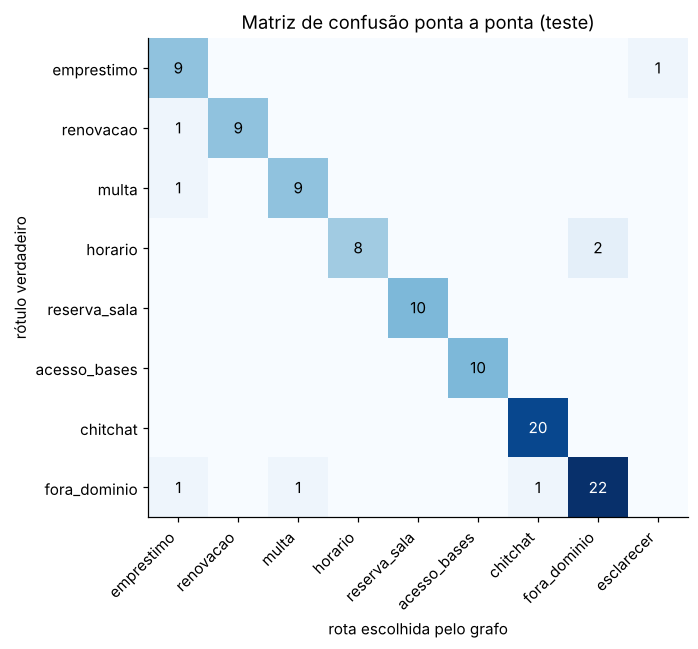

In [35]:
pa = resultado["ponta_a_ponta"]
mc = pd.DataFrame(pa["matriz_confusao"], index=pa["rotulos"], columns=pa["rotulos_previstos"])
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(mc.values, cmap="Blues")
ax.set_xticks(range(len(mc.columns)), mc.columns, rotation=45, ha="right")
ax.set_yticks(range(len(mc.index)), mc.index)
for i in range(mc.shape[0]):
    for j in range(mc.shape[1]):
        if mc.values[i, j]:
            ax.text(j, i, mc.values[i, j], ha="center", va="center",
                    color="white" if mc.values[i, j] > mc.values.max() / 2 else "black")
ax.set_xlabel("rota escolhida pelo grafo")
ax.set_ylabel("rótulo verdadeiro")
ax.set_title("Matriz de confusão ponta a ponta (teste)")
ax.grid(False)
plt.tight_layout()
plt.show()

In [36]:
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]].round(2)

,texto,real,rota,confianca_escopo,confianca_intencao
5,mestrando tem direito a mais livros?,emprestimo,esclarecer,0.95,0.34
16,preciso de mais uns dias com o livro,renovacao,emprestimo,1.00,0.69
26,o cachorro rasgou o livro emprestado,multa,emprestimo,1.00,0.99
34,que horas abre amanha,horario,fora_dominio,0.99,0.00
38,abre de domingo?,horario,fora_dominio,0.71,0.00
89,me resume o livro o cortiço,fora_dominio,emprestimo,0.54,0.58
91,qual a multa por cancelar o plano de celular?,fora_dominio,multa,0.90,0.71
93,vai fazer sol amanhã?,fora_dominio,chitchat,0.49,0.00


> 🔎 **PARE E PENSE.** Os números do teste ficaram **acima** dos da validação
> cruzada. Isso é motivo de comemoração? Lembre-se de que treino e teste do exemplo
> foram escritos pela mesma fonte (um LLM, com o mesmo estilo). O que você espera
> que aconteça quando pessoas reais - com gírias, erros e perguntas que ninguém
> previu - escreverem as mensagens? É por isso que, no trabalho, o **teste precisa
> ser escrito por pessoas** e o professor também avalia com mensagens próprias.

---
## 13. E agora? O trabalho do seu grupo

O que você viu aqui é o **mínimo** - e com dados pequenos demais. No trabalho:

| Exemplo da Biblioteca | Trabalho do grupo |
|---|---|
| tema dado | tema **validado com o professor** |
| ~30 frases por intenção, todas de LLM | ≥ 50 por intenção no treino, ≥ 20% escritas por pessoas |
| teste escrito por LLM | teste **escrito por pessoas**, de preferência de fora do grupo |
| 3 algoritmos, 2 representações | ≥ 3 algoritmos vistos em aula **em cada estágio**, com ajuste de hiperparâmetros |
| limiar escolhido no olho | limiar justificado com dados |
| nenhuma análise de origem dos dados | discutir o efeito de dados de LLM × humanos |
| 8 documentos fictícios | ≥ 5 documentos reais ou plausíveis, com fontes, cobrindo todas as intenções |
| persona de exemplo | persona ajustada com testes |
| - | seção de **uso de IA** no artigo e no vídeo (uso não declarado = nota zero) |

**Roteiro sugerido:**

1. Configure a chave do OpenRouter (`.env`) e rode `python scripts/testar_llm.py`.
2. Preencha o `grupo.yaml` da raiz com o tema e as intenções validados (inclusive a
   `persona`) e reúna os documentos oficiais em `documentos/` (com o `FONTES.md`).
3. Construa `dados/treino.csv` e `dados/teste.csv` (veja `dados/README.md`).
   Opcional: `python scripts/gerar_dados_llm.py` (frases de treino, com revisão) e
   `python scripts/baixar_massive.py` (negativos fáceis).
4. Trabalhe no `notebooks/01_trabalho_grupo.ipynb` (mesma estrutura deste).
5. Converse com o seu bot: `python scripts/conversar.py --depurar`.
6. Avalie: `python scripts/avaliar.py`.
7. Registre todo uso de IA em `USO_DE_IA.md` desde o primeiro dia.
8. Antes de entregar: `python scripts/verificar_entrega.py` - **zero erros**.